In [ ]:
# ============================================================
# SECTION 1: ENVIRONMENT SETUP
# ============================================================

!pip install scikit-learn scipy numpy pandas matplotlib seaborn joblib imbalanced-learn -q


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# ============================================================
# SECTION 2: IMPORTS
# ============================================================

import os
import re
import warnings
from dataclasses import dataclass, field
from typing import Callable, Optional

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.stats import skew, kurtosis
from scipy.fft import fft, fftfreq

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [ ]:
# ============================================================
# SECTION 3: CONFIGURATION
# ============================================================

@dataclass
class Config:
    vibration_folder: str = '/content/drive/MyDrive/DATA/vibration'
    acoustic_folder: str = '/content/drive/MyDrive/DATA/acoustic'
    output_folder: str = '/content/drive/MyDrive/DATA/Output'
    window_size: int = 1024
    test_size: float = 0.2
    random_state: int = RANDOM_STATE
    cv_folds: int = 5
    sampling_rate: float = 25600.0   # VERIFY against your dataset documentation
    knn_param_grid: dict = field(default_factory=lambda: {
        'n_neighbors': [7, 9, 11, 15, 21, 25, 31],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan', 'minkowski']
    })

CONFIG = Config()
os.makedirs(CONFIG.output_folder, exist_ok=True)
print("Configuration initialized.")


Configuration initialized.


In [ ]:
# ============================================================
# SECTION 4: DATA ACQUISITION MODULE
# ============================================================

def parse_label(filename: str) -> Optional[str]:
    """Extract the fault class label from a filename."""
    fname = filename.lower()
    if 'normal' in fname:
        return 'normal'
    elif 'bpfi' in fname:
        return 'inner_fault'
    elif 'bpfo' in fname:
        return 'outer_fault'
    elif 'misalign' in fname:
        return 'misalignment'
    elif 'unbalance' in fname or 'unbal' in fname:
        return 'unbalance'
    return None


def parse_load_condition(filename: str) -> str:
    """Extract the motor load condition (e.g. '0Nm') from a filename."""
    match = re.match(r'(\d+)Nm', filename)
    return f"{match.group(1)}Nm" if match else 'unknown'


def build_file_index(folder: str, extension: str = '.mat') -> pd.DataFrame:
    """Construct an indexed DataFrame of labeled data files within a folder."""
    files = [f for f in os.listdir(folder) if f.endswith(extension)]
    records, unmatched = [], []
    for f in files:
        label = parse_label(f)
        if label is not None:
            records.append({'filename': f, 'label': label, 'load_condition': parse_load_condition(f)})
        else:
            unmatched.append(f)
    if unmatched:
        print(f"Note: {len(unmatched)} file(s) excluded (no matching label keyword): "
              f"{unmatched[:10]}{' ...' if len(unmatched) > 10 else ''}")
    return pd.DataFrame(records).reset_index(drop=True)

print("Data acquisition module loaded.")


Data acquisition module loaded.


In [ ]:
# ============================================================
# SECTION 5: SIGNAL LOADERS
# ============================================================

def load_vibration_signal_single_channel(filepath: str, channel_index: int = 0) -> np.ndarray:
    """Load ONE vibration channel (used for acoustic-style single-channel loading)."""
    mat = sio.loadmat(filepath, squeeze_me=True, struct_as_record=False)
    signal_struct = mat['Signal']
    return np.array(signal_struct.y_values.values)[:, channel_index].flatten()


def load_vibration_signal_all_channels(filepath: str) -> np.ndarray:
    """
    Load ALL 4 vibration channels from a nested-struct .mat file.
    Returns shape (n_samples, 4): [x_housing_A, y_housing_A, x_housing_B, y_housing_B]
    """
    mat = sio.loadmat(filepath, squeeze_me=True, struct_as_record=False)
    signal_struct = mat['Signal']
    return np.array(signal_struct.y_values.values)


def load_acoustic_signal(filepath: str) -> np.ndarray:
    """Load the (single-channel) acoustic signal from a nested-struct .mat file."""
    mat = sio.loadmat(filepath, squeeze_me=True, struct_as_record=False)
    signal_struct = mat['Signal']
    return np.array(signal_struct.y_values.values).flatten()

print("Signal loaders ready.")


Signal loaders ready.


In [ ]:
# ============================================================
# SECTION 6: FEATURE EXTRACTION MODULE
# ============================================================

def extract_time_domain_features(window: np.ndarray) -> list:
    """
    8 time-domain statistical features: mean, std, RMS, peak, peak-to-peak,
    skewness, kurtosis, crest factor. Zero-variance windows return 0 for
    skewness/kurtosis instead of NaN.
    """
    std_dev = np.std(window)
    rms = np.sqrt(np.mean(window ** 2))
    peak = np.max(np.abs(window))
    if std_dev < 1e-10:
        skewness_val, kurtosis_val = 0.0, 0.0
    else:
        skewness_val = skew(window)
        kurtosis_val = kurtosis(window)
        skewness_val = 0.0 if not np.isfinite(skewness_val) else skewness_val
        kurtosis_val = 0.0 if not np.isfinite(kurtosis_val) else kurtosis_val
    return [
        np.mean(window), std_dev, rms, peak,
        np.max(window) - np.min(window),
        skewness_val, kurtosis_val,
        peak / (rms + 1e-8)
    ]


def extract_frequency_features(window: np.ndarray, sampling_rate: float) -> list:
    """
    5 frequency-domain features: dominant frequency, total spectral energy,
    and energy in 3 broad frequency bands (low/mid/high thirds of the
    Nyquist range). Adjust band edges if known bearing fault frequencies
    (BPFO/BPFI) are available for more targeted bands.
    """
    n = len(window)
    fft_vals = np.abs(fft(window))[:n // 2]
    freqs = fftfreq(n, d=1 / sampling_rate)[:n // 2]

    dominant_freq = freqs[np.argmax(fft_vals)] if len(fft_vals) > 0 else 0.0
    spectral_energy = np.sum(fft_vals ** 2)

    band_edges = [0, sampling_rate / 6, sampling_rate / 3, sampling_rate / 2]
    band_energies = []
    for i in range(3):
        mask = (freqs >= band_edges[i]) & (freqs < band_edges[i + 1])
        band_energies.append(np.sum(fft_vals[mask] ** 2) if mask.any() else 0.0)

    return [dominant_freq, spectral_energy] + band_energies


def extract_combined_features(window: np.ndarray, sampling_rate: float) -> list:
    """Time-domain (8) + frequency-domain (5) = 13 features for one channel."""
    return extract_time_domain_features(window) + extract_frequency_features(window, sampling_rate)


def extract_multichannel_features(window_multi_ch: np.ndarray, sampling_rate: float) -> list:
    """
    Apply extract_combined_features independently to each channel and
    concatenate. window_multi_ch shape: (window_size, n_channels).
    """
    all_features = []
    for ch in range(window_multi_ch.shape[1]):
        all_features.extend(extract_combined_features(window_multi_ch[:, ch], sampling_rate))
    return all_features


VIBRATION_FEATURE_NAMES = [
    f'{feat}_ch{ch}' for ch in range(4)
    for feat in ['mean', 'std_dev', 'rms', 'peak', 'peak_to_peak', 'skewness', 'kurtosis',
                 'crest_factor', 'dominant_freq', 'spectral_energy', 'band_low', 'band_mid', 'band_high']
]
ACOUSTIC_FEATURE_NAMES = [
    f'{feat}' for feat in ['mean', 'std_dev', 'rms', 'peak', 'peak_to_peak', 'skewness', 'kurtosis',
                            'crest_factor', 'dominant_freq', 'spectral_energy', 'band_low', 'band_mid', 'band_high']
]

print(f"Feature extraction module loaded. Vibration: {len(VIBRATION_FEATURE_NAMES)} features. "
      f"Acoustic: {len(ACOUSTIC_FEATURE_NAMES)} features.")


Feature extraction module loaded. Vibration: 52 features. Acoustic: 13 features.


In [ ]:
# ============================================================
# SECTION 7: SEGMENTATION AND DATASET BUILDERS
# ============================================================

def segment_signal(signal_2d: np.ndarray, window_size: int, overlap: float = 0.0) -> np.ndarray:
    """
    Segment a signal into fixed-length windows. Works for both single-channel
    (n_samples,) and multi-channel (n_samples, n_channels) input by reshaping
    1D input internally.
    """
    is_1d = (signal_2d.ndim == 1)
    if is_1d:
        signal_2d = signal_2d.reshape(-1, 1)

    step = max(1, int(window_size * (1 - overlap)))
    n_windows = max(0, (signal_2d.shape[0] - window_size) // step + 1)
    windows = np.array([signal_2d[i * step: i * step + window_size, :] for i in range(n_windows)])

    return windows[:, :, 0] if is_1d else windows


def build_feature_matrix_all(file_index: pd.DataFrame, folder: str, loader_fn: Callable,
                               feature_fn: Callable, window_size: int, sampling_rate: float,
                               multichannel: bool) -> tuple:
    """
    Build the feature matrix and label vector from ALL files (window-level
    split will be performed afterward — see Section 8).

    Parameters
    ----------
    loader_fn : Callable
        Function that loads a raw signal (1D for single-channel, 2D for multi-channel).
    feature_fn : Callable
        Function that extracts a feature vector from one window.
    multichannel : bool
        If True, windows are (window_size, n_channels) and feature_fn expects
        (window, sampling_rate). If False, windows are (window_size,) and
        feature_fn expects (window, sampling_rate) as well (single-channel combined features).
    """
    features, labels = [], []
    failed_files = []

    for _, row in file_index.iterrows():
        filepath = os.path.join(folder, row['filename'])
        try:
            signal = loader_fn(filepath)
        except Exception as exc:
            failed_files.append((row['filename'], str(exc)))
            continue

        windows = segment_signal(signal, window_size, overlap=0.0)
        for window in windows:
            features.append(feature_fn(window, sampling_rate))
            labels.append(row['label'])

    if failed_files:
        print(f"Warning: {len(failed_files)} file(s) failed to load:")
        for fname, err in failed_files:
            print(f"  - {fname}: {err}")

    return np.array(features), np.array(labels)

print("Dataset builder ready.")


Dataset builder ready.


In [ ]:
# ============================================================
# SECTION 8: WINDOW-LEVEL SPLIT
# ============================================================

def split_windows(X: np.ndarray, y: np.ndarray, test_size: float, random_state: int) -> tuple:
    """Split at the WINDOW level, stratified by class."""
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)

print("Window-level split function loaded.")


Window-level split function loaded.


In [ ]:
# ============================================================
# SECTION 9: MODEL TRAINING AND EVALUATION MODULE
# ============================================================

class KNNFaultClassifierWindowLevel:
    """
    KNN pipeline for a window-level train/test split. Applies SMOTE to the
    training set, tunes hyperparameters via StratifiedKFold cross-validation
    scored on weighted F1 (robust to class imbalance), then evaluates on
    the held-out window-level test set.
    """

    def __init__(self, sensor_name: str, config: Config):
        self.sensor_name = sensor_name
        self.config = config
        self.scaler = StandardScaler()

    def fit(self, X_train, y_train, X_test, y_test, use_smote: bool = True):
        self.X_train, self.y_train = X_train, y_train
        self.X_test, self.y_test = X_test, y_test

        self.X_train_scaled = self.scaler.fit_transform(self.X_train)
        self.X_test_scaled = self.scaler.transform(self.X_test)

        if use_smote:
            min_class_size = pd.Series(self.y_train).value_counts().min()
            k_neighbors = max(1, min(5, min_class_size - 1))
            smote = SMOTE(random_state=self.config.random_state, k_neighbors=k_neighbors)
            X_train_final, y_train_final = smote.fit_resample(self.X_train_scaled, self.y_train)
            print(f"[{self.sensor_name}] SMOTE applied: {len(self.y_train)} -> {len(y_train_final)} "
                  f"training samples (k_neighbors={k_neighbors})")
        else:
            X_train_final, y_train_final = self.X_train_scaled, self.y_train

        cv_strategy = StratifiedKFold(n_splits=self.config.cv_folds, shuffle=True,
                                        random_state=self.config.random_state)
        grid_search = GridSearchCV(
            estimator=KNeighborsClassifier(),
            param_grid=self.config.knn_param_grid,
            cv=cv_strategy,
            scoring='f1_weighted',
            n_jobs=-1
        )
        grid_search.fit(self.X_train_scaled, self.y_train)

        self.grid_search_results = grid_search
        self.best_model = KNeighborsClassifier(**grid_search.best_params_)
        self.best_model.fit(X_train_final, y_train_final)

        y_pred = self.best_model.predict(self.X_test_scaled)
        self.y_pred = y_pred
        precision, recall, f1, _ = precision_recall_fscore_support(
            self.y_test, y_pred, average='weighted', zero_division=0
        )
        self.metrics = {
            'accuracy': accuracy_score(self.y_test, y_pred),
            'precision': precision, 'recall': recall, 'f1_score': f1,
            'best_params': grid_search.best_params_,
            'cv_best_score': grid_search.best_score_
        }
        return self

    def summary(self) -> pd.DataFrame:
        return pd.DataFrame([{
            'Sensor': self.sensor_name,
            'Best K': self.metrics['best_params']['n_neighbors'],
            'Weights': self.metrics['best_params']['weights'],
            'Metric': self.metrics['best_params']['metric'],
            'CV F1 (window-level)': round(self.metrics['cv_best_score'], 4),
            'Test Accuracy': round(self.metrics['accuracy'], 4),
            'Precision': round(self.metrics['precision'], 4),
            'Recall': round(self.metrics['recall'], 4),
            'F1-Score': round(self.metrics['f1_score'], 4)
        }])

    def print_report(self):
        print(f"{'=' * 60}")
        print(f"KNN Classification Report — {self.sensor_name} (WINDOW-LEVEL SPLIT)")
        print(f"{'=' * 60}")
        print(f"Best hyperparameters: {self.metrics['best_params']}")
        print(f"CV weighted-F1 (window-level, leakage-prone): {self.metrics['cv_best_score']:.4f}")
        print(f"Test accuracy (window-level, leakage-prone): {self.metrics['accuracy']:.4f}\n")
        print(classification_report(self.y_test, self.y_pred, zero_division=0))

print("Model training module loaded.")


Model training module loaded.


In [ ]:
# ============================================================
# SECTION 10: VISUALIZATION MODULE
# ============================================================

def plot_confusion_matrix(clf, save_path: str = None):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(clf.y_test, clf.y_pred, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'Confusion Matrix — KNN ({clf.sensor_name}, window-level split)')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def plot_feature_importance_proxy(X, y, feature_names, sensor_name, save_path=None, top_n=15):
    """
    KNN has no built-in feature importance, so this uses a quick Random
    Forest fit purely as a DIAGNOSTIC proxy to see which features carry
    the most class-discriminative signal — not used for classification itself.
    """
    from sklearn.ensemble import RandomForestClassifier
    rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf.fit(StandardScaler().fit_transform(X), y)
    importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(top_n)

    plt.figure(figsize=(8, 6))
    importances.sort_values().plot(kind='barh', color='seagreen')
    plt.title(f'Top {top_n} Features by Discriminative Power (RF proxy) — {sensor_name}')
    plt.xlabel('Relative Importance')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def plot_pca_projection(X, y, sensor_name, save_path=None):
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X_scaled)
    plt.figure(figsize=(7, 6))
    for label in np.unique(y):
        mask = y == label
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label, alpha=0.6, s=15)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)')
    plt.title(f'PCA Projection — {sensor_name} (all windows)')
    plt.legend(title='Class')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

print("Visualization module loaded.")


Visualization module loaded.


In [ ]:
# ============================================================
# SECTION 11a: VIBRATION — FILE INDEX AND FEATURE EXTRACTION
# ============================================================

vibration_index = build_file_index(CONFIG.vibration_folder)
print("Vibration file distribution (all files):")
print(vibration_index['label'].value_counts())

X_vibration_all, y_vibration_all = build_feature_matrix_all(
    vibration_index, CONFIG.vibration_folder,
    loader_fn=load_vibration_signal_all_channels,
    feature_fn=extract_multichannel_features,
    window_size=CONFIG.window_size,
    sampling_rate=CONFIG.sampling_rate,
    multichannel=True
)
print(f"\nVibration feature matrix (all windows): {X_vibration_all.shape}  "
      f"({X_vibration_all.shape[1]} features per window)")
print(pd.Series(y_vibration_all).value_counts())
print("\nNaN check:", np.isnan(X_vibration_all).sum(), " Inf check:", np.isinf(X_vibration_all).sum())


Vibration file distribution (all files):
label
unbalance       15
inner_fault      9
outer_fault      9
misalignment     9
normal           3
Name: count, dtype: int64

Vibration feature matrix (all windows): (112500, 52)  (52 features per window)
unbalance       45000
misalignment    27000
inner_fault     13500
outer_fault     13500
normal          13500
Name: count, dtype: int64

NaN check: 0  Inf check: 0


In [ ]:
# ============================================================
# SECTION 11b: VIBRATION — WINDOW-LEVEL SPLIT
# ============================================================

X_vibration_train, X_vibration_test, y_vibration_train, y_vibration_test = split_windows(
    X_vibration_all, y_vibration_all, CONFIG.test_size, CONFIG.random_state
)
print(f"Training windows: {X_vibration_train.shape[0]}  |  Test windows: {X_vibration_test.shape[0]}")
print("\nTraining label distribution:")
print(pd.Series(y_vibration_train).value_counts())
print("\nTest label distribution:")
print(pd.Series(y_vibration_test).value_counts())


Training windows: 90000  |  Test windows: 22500

Training label distribution:
unbalance       36000
misalignment    21600
inner_fault     10800
normal          10800
outer_fault     10800
Name: count, dtype: int64

Test label distribution:
unbalance       9000
misalignment    5400
normal          2700
outer_fault     2700
inner_fault     2700
Name: count, dtype: int64


In [ ]:
# ============================================================
# SECTION 11c: VIBRATION — MODEL TRAINING
# ============================================================

vibration_classifier = KNNFaultClassifierWindowLevel(sensor_name='Vibration', config=CONFIG)
vibration_classifier.fit(X_vibration_train, y_vibration_train, X_vibration_test, y_vibration_test, use_smote=True)
vibration_classifier.print_report()


[Vibration] SMOTE applied: 90000 -> 180000 training samples (k_neighbors=5)
KNN Classification Report — Vibration (WINDOW-LEVEL SPLIT)
Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 31, 'weights': 'distance'}
CV weighted-F1 (window-level, leakage-prone): 0.9519
Test accuracy (window-level, leakage-prone): 0.9000

              precision    recall  f1-score   support

 inner_fault       1.00      1.00      1.00      2700
misalignment       1.00      1.00      1.00      5400
      normal       0.55      0.88      0.68      2700
 outer_fault       1.00      1.00      1.00      2700
   unbalance       0.96      0.79      0.86      9000

    accuracy                           0.90     22500
   macro avg       0.90      0.93      0.91     22500
weighted avg       0.93      0.90      0.91     22500



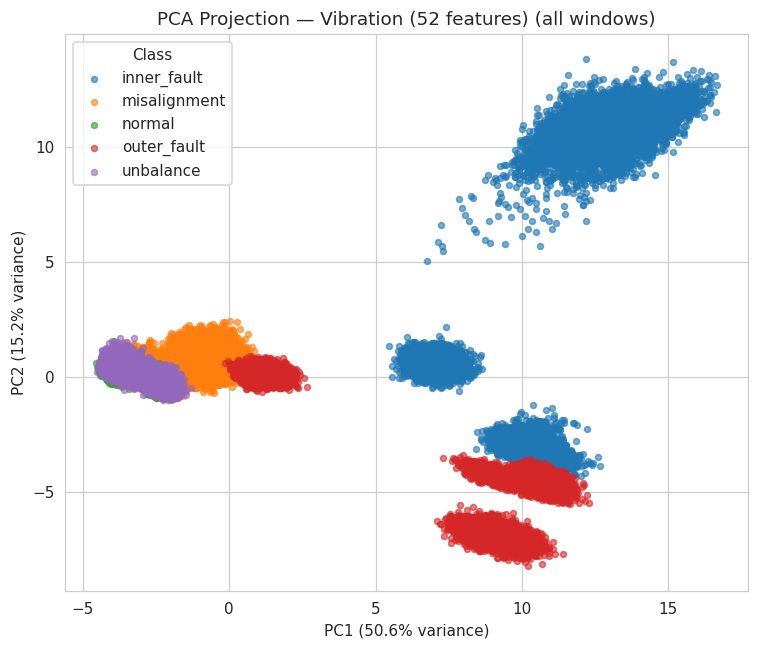

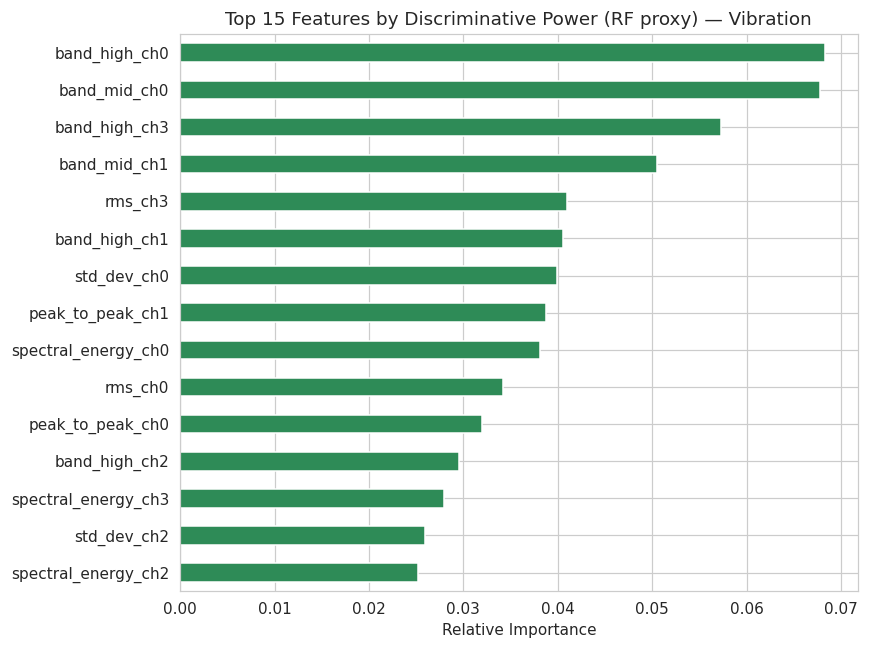

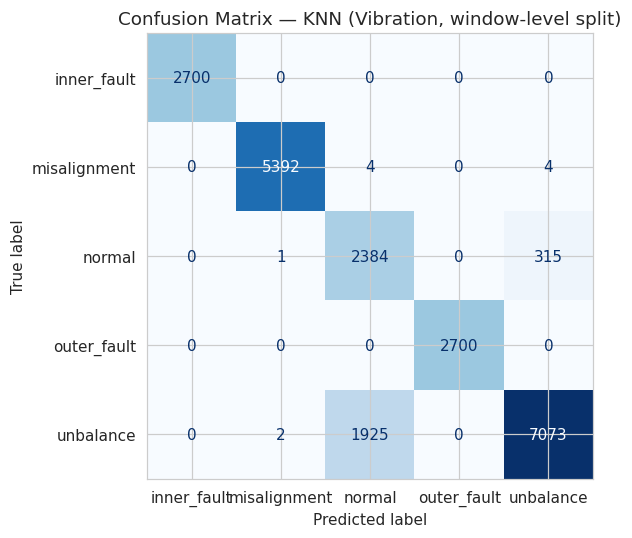

In [ ]:
# ============================================================
# SECTION 11d: VIBRATION — VISUALIZATION
# ============================================================

out = CONFIG.output_folder
plot_pca_projection(X_vibration_all, y_vibration_all, 'Vibration (52 features)',
                     save_path=f'{out}/vibration_multichannel_pca.png')
plot_feature_importance_proxy(X_vibration_all, y_vibration_all, VIBRATION_FEATURE_NAMES, 'Vibration',
                               save_path=f'{out}/vibration_feature_importance.png')
plot_confusion_matrix(vibration_classifier,
                       save_path=f'{out}/vibration_confusion_matrix_multichannel.png')
